# MLOps Assignment: Predictive Maintenance Classification
### Starter Notebook

**Domain:** Industrial IoT / Manufacturing
**Task:** Multi-class failure type prediction
**Tools:** Pandera, MLflow, Optuna, Evidently, SHAP

---

## Business Context

A heavy-equipment manufacturer runs 10,000+ machines on the shop floor.
Each machine continuously streams six sensor readings. When a machine fails,
production halts - at a cost of ₹8-15 lakh per hour of downtime.

Your job is to build a full MLOps pipeline that:
1. Validates incoming sensor data before it enters the pipeline (Pandera)
2. Trains and tracks a multi-class failure classifier (MLflow)
3. Tunes hyperparameters and registers the best model (Optuna + MLflow Registry)
4. Monitors the deployed model for distributional shift (Evidently)
5. Explains why the model predicts a specific failure type (SHAP)

**Files provided:**
- `data/train.csv`   - 6,993 labelled sensor readings (historical baseline)
- `data/current.csv` - 1,499 readings from the current stable production batch
- `data/stress.csv`  - 1,499 readings from a heavy-load production period

**Failure classes:**

| Code | Name | Description |
|------|------|-------------|
| 0 | No Failure | Machine operating normally |
| 1 | TWF | Tool Wear Failure |
| 2 | HDF | Heat Dissipation Failure |
| 3 | PWF | Power Failure |
| 4 | OSF | Overstrain Failure |

> Visual anchor: use the generated `eda_distributions.png` early (Section 1.3) to ground your expectations before drift and SHAP interpretation.
> Stress-batch goal: diagnose *why* the model is stale under shifted operating conditions, not to force perfect predictions on `stress.csv`.
> **Submission:** Submit this notebook (`.ipynb`) with all cells executed.
> Do not change the section structure or remove any markdown cells.

## **1. Data Loading, Schema Validation & EDA** <font color=red>[15 marks]</font>

### **1.1** <font color=red>[3 marks]</font> Load the datasets

Load `train.csv`, `current.csv`, and `stress.csv` from the `data/` folder.
Print the shape of each and display the first 5 rows of the training set.


In [1]:
import warnings
warnings.filterwarnings('ignore')
import os
os.environ['DISABLE_PANDERA_IMPORT_WARNING'] = 'True'

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# TODO: Load the three datasets
train   = pd.read_csv('data/train.csv')
current = pd.read_csv('data/current.csv')
stress  = pd.read_csv('data/stress.csv')

# TODO: Print shapes
print(f'train  : {train.shape}')
print(f'current: {current.shape}')
print(f'stress : {stress.shape}')

CLASS_NAMES = {0: 'No Failure', 1: 'TWF', 2: 'HDF', 3: 'PWF', 4: 'OSF'}

# TODO: Display first 5 rows of train
train.head(5)


train  : (6993, 7)
current: (1499, 7)
stress : (1499, 7)


,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Failure_Type
0,L,302.5,311.1,1499,38.8,135,0
1,L,297.3,308.4,1469,46.7,65,0
2,L,297.3,308.5,1504,42.0,142,0
3,L,299.6,309.5,1803,27.7,159,0
4,L,301.1,311.1,1387,53.1,188,0


### **1.2** <font color=red>[5 marks]</font> Define and apply a Pandera schema

Define a `DataFrameSchema` enforcing the domain constraints below.
Validate `train` and `current` (must pass). Validate `stress` with `lazy=True`.

| Column | Type | Constraint |
|--------|------|------------|
| Type | str | one of L, M, H |
| Air temperature | float | [295.0, 305.0] K |
| Process temperature | float | [305.0, 315.0] K |
| Rotational speed | int64 | [1000, 2900] rpm |
| Torque | float | [3.0, 80.0] Nm |
| Tool wear | int64 | [0, 253] min |
| Failure_Type | int64 | 0, 1, 2, 3, 4 |


> `stress.csv` may still pass schema validation. That is fine: it is designed to be valid but drifted.
> Hint: valid data can still be statistically unusual. Before Section 3, compare the mean of `Rotational speed` in `current` vs `stress`.

In [2]:
import pandera as pa
from pandera import Column, DataFrameSchema, Check

# TODO: Define the schema
schema = DataFrameSchema({
    'Type': Column(str, Check.isin(['L', 'M', 'H'])),
    'Air temperature': Column(float, Check.in_range(295.0, 305.0)),
    'Process temperature': Column(float, Check.in_range(305.0, 315.0)),
    'Rotational speed': Column(np.int64, Check.in_range(1000, 2900)),
    'Torque': Column(float, Check.in_range(3.0, 80.0)),
    'Tool wear': Column(np.int64, Check.in_range(0, 253)),
    'Failure_Type': Column(np.int64, Check.isin([0, 1, 2, 3, 4])),
})

def fix_dtypes(df):
    df = df.copy()
    df['Rotational speed'] = df['Rotational speed'].astype('int64')
    df['Tool wear']        = df['Tool wear'].astype('int64')
    df['Failure_Type']     = df['Failure_Type'].astype('int64')
    return df

train   = fix_dtypes(train)
current = fix_dtypes(current)
stress  = fix_dtypes(stress)

# TODO: Validate train and current
schema.validate(train)
schema.validate(current)

# TODO: Validate stress with lazy=True and print violation summary
schema.validate(stress, lazy=True)


,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Failure_Type
0,L,301.0,310.9,1523,44.3,93,0
1,M,297.3,308.4,1473,44.4,126,0
2,M,299.0,310.0,1320,63.1,171,0
3,M,304.3,313.3,1503,42.8,66,0
4,L,298.4,309.5,1313,55.1,163,0
...,...,...,...,...,...,...,...
1494,L,302.2,311.5,1440,45.1,145,0
1495,M,295.6,306.1,1608,31.7,166,0
1496,L,303.3,312.5,1905,25.7,186,0
1497,L,298.8,310.1,1499,41.6,231,0


### **1.3** <font color=red>[4 marks]</font> Exploratory Data Analysis

1. Print the class distribution of `Failure_Type`. Is it balanced?
2. Plot the distribution of `Torque` and `Tool wear` split by failure class (failures only).
3. Print the `Type` (L/M/H) distribution.


Failure_Type
No Failure    6762
TWF             30
HDF             76
PWF             56
OSF             69
Name: count, dtype: int64


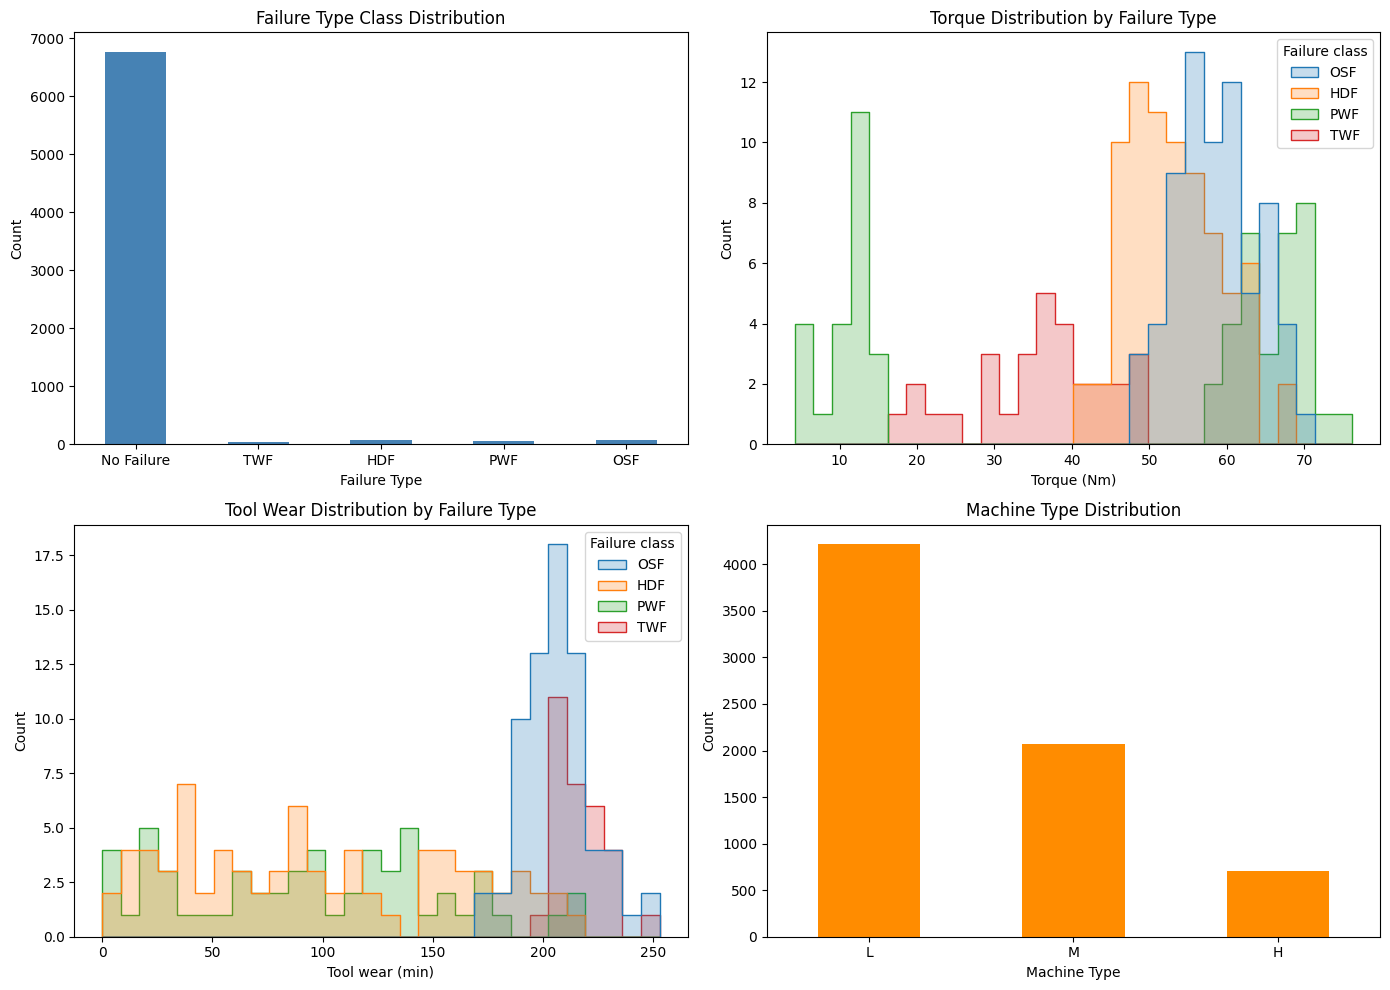

In [3]:
class_counts = train['Failure_Type'].value_counts().reindex(CLASS_NAMES.keys(), fill_value=0)
print(class_counts.rename(index=CLASS_NAMES))

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Failure class distribution
class_counts.rename(index=CLASS_NAMES).plot(
    kind='bar', color='steelblue', ax=axes[0, 0]
)
axes[0, 0].set_title('Failure Type Class Distribution')
axes[0, 0].set_xlabel('Failure Type')
axes[0, 0].set_ylabel('Count')
axes[0, 0].tick_params(axis='x', rotation=0)

failures = train.loc[train['Failure_Type'] != 0].copy()
failures['Failure class'] = failures['Failure_Type'].map(CLASS_NAMES)

# Torque distribution by failure class
sns.histplot(
    data=failures, x='Torque', hue='Failure class',
    bins=30, element='step', common_bins=True, ax=axes[0, 1]
)
axes[0, 1].set_title('Torque Distribution by Failure Type')
axes[0, 1].set_xlabel('Torque (Nm)')
axes[0, 1].set_ylabel('Count')

# Tool wear distribution by failure class
sns.histplot(
    data=failures, x='Tool wear', hue='Failure class',
    bins=30, element='step', common_bins=True, ax=axes[1, 0]
)
axes[1, 0].set_title('Tool Wear Distribution by Failure Type')
axes[1, 0].set_xlabel('Tool wear (min)')
axes[1, 0].set_ylabel('Count')

# Machine type distribution
type_counts = train['Type'].value_counts().reindex(['L', 'M', 'H'], fill_value=0)
type_counts.plot(kind='bar', color='darkorange', ax=axes[1, 1])
axes[1, 1].set_title('Machine Type Distribution')
axes[1, 1].set_xlabel('Machine Type')
axes[1, 1].set_ylabel('Count')
axes[1, 1].tick_params(axis='x', rotation=0)

fig.tight_layout()
fig.savefig('eda_distributions.png', dpi=300, bbox_inches='tight')
plt.show()

### **1.4** <font color=red>[3 marks]</font> Feature Engineering

Compute the following derived features for all three datasets:

**Mechanical power** (Watts):
$$P = \text{Torque} \times \frac{\text{Rotational speed} \times 2\pi}{60}$$

**Temperature differential**:
$$\Delta T = \text{Process temperature} - \text{Air temperature}$$

Print the mean of each new feature grouped by `Failure_Type`.


In [4]:
def engineer_features(df):
    df = df.copy()
    df['Power_W'] = df['Torque'] * (df['Rotational speed'] * 2 * np.pi / 60)
    df['Temp_diff'] = df['Process temperature'] - df['Air temperature']
    return df    

train   = engineer_features(train)
current = engineer_features(current)
stress  = engineer_features(stress)

In [ ]:
# TODO: Print grouped mean
for name, df in [('train', train), ('current', current), ('stress', stress)]:
        print(f'\n{name} feature means by Failure_Type:')
        print(df.groupby('Failure_Type')[['Power_W', 'Temp_diff']].mean())
        


train feature means by Failure_Type:
                  Power_W  Temp_diff
Failure_Type                        
0             6248.240886  10.013812
1             5763.094643   9.966667
2             7403.545453   8.228947
3             6664.382233   9.823214
4             8216.074774  10.072464

current feature means by Failure_Type:
                  Power_W  Temp_diff
Failure_Type                        
0             6253.901580  10.103244
1             6263.904904   9.471429
2             7112.855056   8.306250
3             7633.425249  10.283333
4             8401.126297  10.013333

stress feature means by Failure_Type:
                  Power_W  Temp_diff
Failure_Type                        
0             6762.740972   9.974253
1             6213.171424   9.666667
2             8042.586225   8.211765
3             7570.226004  10.133333
4             8176.587089   9.986207


## **2. Experiment Tracking & Model Selection** <font color=red>[15 marks]</font>

### **2.1** <font color=red>[2 marks]</font> Setup: features, split, SMOTE

Use the features below. Apply a stratified 80/20 train-val split (random_state=42).
Apply SMOTE to the training split only. Print the post-SMOTE class distribution.

```
FEATURES = ['Type_enc', 'Air temperature', 'Process temperature',
            'Rotational speed', 'Torque', 'Tool wear', 'Power_W', 'Temp_diff']
```

> In a markdown cell below the code, explain in 2–3 sentences why SMOTE is applied
> only to the training split and not the validation set.


In [6]:
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE

# TODO: Encode Type column
le = LabelEncoder()
train['Type_enc']   = le.fit_transform(train['Type'])
current['Type_enc'] = le.transform(current['Type'])
stress['Type_enc']  = le.transform(stress['Type'])

FEATURES = ['Type_enc', 'Air temperature', 'Process temperature',
            'Rotational speed', 'Torque', 'Tool wear', 'Power_W', 'Temp_diff']


In [7]:
import joblib

joblib.dump(le, 'label_encoder.pkl')

['label_encoder.pkl']

In [8]:
#TODO: Define X and y
X = train[FEATURES]
y = train['Failure_Type']

# TODO: Train-val split
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Pre-SMOTE class distribution:")
print(y_train.value_counts())

# TODO: Apply SMOTE (k_neighbors=3, random_state=42)
smote = SMOTE(k_neighbors=3, random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

# TODO: Print post-SMOTE class distribution
print("Post-SMOTE class distribution:")
print(y_train_resampled.value_counts())


Pre-SMOTE class distribution:
Failure_Type
0    5409
2      61
4      55
3      45
1      24
Name: count, dtype: int64
Post-SMOTE class distribution:
Failure_Type
0    5409
3    5409
4    5409
2    5409
1    5409
Name: count, dtype: int64


*Your explanation here: why is SMOTE applied only on the training split?*          

SMOTE is applied on training split to help model learn the minority class patterns. If it is applied on test split it will cause data leakage, model's evaluation metrics will look near-perfect and when deployed in production the model's performance will collapse drastically. 

### **2.2** <font color=red>[8 marks]</font> Train and log 4 models with MLflow

Train and evaluate:
- Logistic Regression
- Random Forest (n_estimators=100)
- XGBoost (n_estimators=100)
- LightGBM (n_estimators=100)

MLflow experiment name: `PredMaint_ModelSelection`

For each run log: `model` (param), `macro_f1`, `weighted_f1`, `accuracy` (metrics),
and per-class F1 for all 5 classes. Print a comparison table. Pick the best model by macro F1.


In [9]:
import mlflow
import mlflow.sklearn
from sklearn.metrics import f1_score, accuracy_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier


models_to_run = {
    'LogisticRegression': Pipeline([
        ('scaler', StandardScaler()),
        ('lr', LogisticRegression(max_iter=2000, random_state=42,
                                  class_weight='balanced'))
    ]),
    'RandomForest':       RandomForestClassifier(n_estimators=100, random_state=42,
                                                  class_weight='balanced'),
    'XGBoost':            XGBClassifier(n_estimators=100, random_state=42,
                                         eval_metric='mlogloss', verbosity=0),
    'LightGBM':           LGBMClassifier(n_estimators=100, random_state=42,
                                          class_weight='balanced', verbose=-1),
}



In [15]:
# TODO: For each model:
#   - Start an MLflow run
#   - Fit on X_res, y_res
#   - Predict on X_val
#   - Compute and log macro_f1, weighted_f1, accuracy, per-class F1
#   - Log the model artefact (use input_example=X_val.iloc[:5])

# TODO: Print comparison table
# TODO: Identify best model by macro F1
mlflow.set_experiment(experiment_name="Predictive_Maint_ModelSelection")
mlflow.set_tracking_uri('sqlite:///mlflow.db')

CLASS_LIST = [0, 1, 2, 3, 4]
results = {}

comparison = []

for model_name, model in models_to_run.items():
    model.fit(X_train_resampled, y_train_resampled)
    y_pred = model.predict(X_val)

    metrics = {
        'macro_f1': f1_score(y_val, y_pred, labels=CLASS_LIST,
                              average='macro', zero_division=0),
        'weighted_f1': f1_score(y_val, y_pred, labels=CLASS_LIST,
                                average='weighted', zero_division=0),
        'accuracy': accuracy_score(y_val, y_pred),
        
    }

    with mlflow.start_run(run_name=model_name):
        mlflow.log_param('model', model_name)
        mlflow.log_metrics(metrics)

        per_class_f1 = f1_score(
            y_val, y_pred, labels=CLASS_LIST, average=None, zero_division=0
        )
        for class_id, score in zip(CLASS_LIST, per_class_f1):
            mlflow.log_metric(f'f1_class_{class_id}', score)

        mlflow.sklearn.log_model(
            model,
            artifact_path='model',
            input_example=X_val.iloc[:5]
        )

    results[model_name] = metrics
    comparison.append({'model': model_name, **metrics})

comparison_table = pd.DataFrame(comparison).sort_values(
    'macro_f1', ascending=False
)
display(comparison_table)

best_name = comparison_table.iloc[0]['model']
best_model = models_to_run[best_name]
print(f"Best model by macro F1: {best_name} "
      f"({results[best_name]['macro_f1']:.4f})")

# Used later to compare Optuna's tuned XGBoost with baseline XGBoost.
baseline_xgb_macro_f1 = results['XGBoost']['macro_f1']

,model,macro_f1,weighted_f1,accuracy
2,XGBoost,0.748062,0.985147,0.984274
1,RandomForest,0.735542,0.985459,0.984989
3,LightGBM,0.729645,0.985088,0.984274
0,LogisticRegression,0.531231,0.932771,0.904217


Best model by macro F1: XGBoost (0.7481)


### **2.3** <font color=red>[5 marks]</font> Optuna tuning + MLflow Model Registry

Run an Optuna study (30 trials, `TPESampler(seed=42)`) tuning XGBoost hyperparameters.
Optimise for `macro_f1` on `X_val`.

MLflow experiment: `PredMaint_Optuna`

Register the best model as `PredMaint_XGBoost` and promote it to the `production` alias.
Print the improvement in macro F1 over the baseline XGBoost.


In [16]:
import optuna
import joblib

optuna.logging.set_verbosity(optuna.logging.WARNING)
mlflow.set_experiment('PredMaint_Optuna')

def objective(trial):
    params = {
        'n_estimators':      trial.suggest_int('n_estimators', 100, 500),
        'max_depth':         trial.suggest_int('max_depth', 3, 10),
        'learning_rate':     trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'min_child_weight':  trial.suggest_float('min_child_weight', 1.0, 10.0),
        'subsample':         trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree':  trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'gamma':             trial.suggest_float('gamma', 0.0, 2.0),
        'reg_alpha':         trial.suggest_float('reg_alpha', 1e-8, 1.0, log=True),
        'reg_lambda':        trial.suggest_float('reg_lambda', 1e-8, 5.0, log=True),
        'random_state': 42, 'eval_metric': 'mlogloss', 'verbosity': 0,
    }
    # TODO: Train XGBoost model, return macro_f1 on X_val

    model = XGBClassifier(**params)
    model.fit(X_train_resampled, y_train_resampled)
    y_pred = model.predict(X_val)
    return f1_score(
        y_val, y_pred, labels=CLASS_LIST, average='macro', zero_division=0
    )


study = optuna.create_study(direction='maximize',
                            sampler=optuna.samplers.TPESampler(seed=42))


# TODO: Run study.optimize
study.optimize(objective, n_trials=30)

# TODO: Train final best model
best_params = {
    **study.best_params,
    'random_state': 42,
    'eval_metric': 'mlogloss',
    'verbosity': 0,
}

final_model = XGBClassifier(**best_params)
final_model.fit(X_train_resampled, y_train_resampled)

y_pred_final = final_model.predict(X_val)
final_macro_f1 = f1_score(
    y_val, y_pred_final, labels=CLASS_LIST,
    average='macro', zero_division=0
)


# TODO: Log to MLflow, register as 'PredMaint_XGBoost', promote to production alias
with mlflow.start_run(run_name='XGBoost_Optuna_Best') as run:
    mlflow.log_params(best_params)
    mlflow.log_metric('macro_f1', final_macro_f1)
    mlflow.log_metric(
        'improvement_over_baseline',
        final_macro_f1 - baseline_xgb_macro_f1
    )

    model_info = mlflow.xgboost.log_model(
        final_model,
        artifact_path='model',
        input_example=X_val.iloc[:5],
        registered_model_name='PredMaint_XGBoost'
    )

client = mlflow.tracking.MlflowClient()
versions = client.search_model_versions(
    f"name='PredMaint_XGBoost' and run_id='{run.info.run_id}'"
)
model_version = max(versions, key=lambda version: int(version.version))
client.set_registered_model_alias(
    'PredMaint_XGBoost', 'production', model_version.version
)

# TODO: Save with joblib.dump
best_model = final_model
joblib.dump(best_model, 'best_model.pkl')

print(f'Best Optuna macro F1: {study.best_value:.4f}')
print(f'Final macro F1: {final_macro_f1:.4f}')
print(f'Improvement over baseline XGBoost: '
      f'{final_macro_f1 - baseline_xgb_macro_f1:.4f}')
print(f"Registered version {model_version.version} with alias 'production'.")

2026/10/22 11:42:59 INFO mlflow.tracking.fluent: Experiment with name 'PredMaint_Optuna' does not exist. Creating a new experiment.


Best Optuna macro F1: 0.7610
Final macro F1: 0.7610
Improvement over baseline XGBoost: 0.0129
Registered version 1 with alias 'production'.


Successfully registered model 'PredMaint_XGBoost'.
Created version '1' of model 'PredMaint_XGBoost'.


## **3. Drift Detection & Monitoring** <font color=red>[10 marks]</font>

> Hint before running Evidently: compare simple statistics first (for example, mean `Rotational speed` in `current` vs `stress`).
> Reminder: passing Pandera only means values are valid; it does **not** mean the batch is in-distribution.
> Section objective: identify why the deployed model is stale on stress conditions.

### **3.1** <font color=red>[4 marks]</font> Evidently — current batch

Reference: `train[FEAT_COLS]` | Current: `current[FEAT_COLS]`

```
FEAT_COLS = ['Air temperature', 'Process temperature',
             'Rotational speed', 'Torque', 'Tool wear']
```

Run `DataDriftPreset`. Save HTML to `drift_current.html`.
Report: drift detected? How many features drifted?


In [17]:
# Compare feature means across the stable current batch and the stress batch
compare_features = [
    'Air temperature', 'Process temperature',
    'Rotational speed', 'Torque', 'Tool wear'
]

mean_comparison = pd.DataFrame({
    'current_mean': current[compare_features].mean(),
    'stress_mean': stress[compare_features].mean(),
})
mean_comparison['delta (stress - current)'] = (
    mean_comparison['stress_mean'] - mean_comparison['current_mean']
)

display(mean_comparison.round(2))

,current_mean,stress_mean,delta (stress - current)
Air temperature,299.92,300.05,0.13
Process temperature,310.00,310.01,0.00
Rotational speed,1530.17,1497.07,-33.09
Torque,40.22,44.72,4.50
Tool wear,108.20,148.87,40.67


In [20]:
from evidently.legacy.report import Report
from evidently.legacy.metric_preset import DataDriftPreset

FEAT_COLS = ['Air temperature', 'Process temperature',
             'Rotational speed', 'Torque', 'Tool wear']

# TODO: Run Evidently on current batch, save drift_current.html, print summary
report = Report(metrics=[DataDriftPreset()])
report.run(
    reference_data=train[FEAT_COLS],
    current_data=current[FEAT_COLS]
)
report.save_html("drift_current.html")

results = report.as_dict()["metrics"]
dataset_result = next(
    item["result"] for item in results
    if "dataset_drift" in item.get("result", {})
)

print("Current batch drift summary")
print(f"Drift detected: {dataset_result['dataset_drift']}")
print(f"Drifted features: {dataset_result['number_of_drifted_columns']} "
      f"of {dataset_result['number_of_columns']}")

Current batch drift summary
Drift detected: False
Drifted features: 0 of 5


### **3.2** <font color=red>[4 marks]</font> Evidently - stress batch

Repeat for `stress.csv`. Use `ColumnDriftMetric` for individual feature scores.
Save as `drift_stress.html`.
Print a table: feature | drift detected | Wasserstein score | ref mean | current mean | delta.

Focus question: this section is about diagnosing *staleness risk* (what shifted and why), not "making stress predictions look good."

In [21]:
from evidently.legacy.metrics.data_drift.dataset_drift_metric import DatasetDriftMetric
from evidently.legacy.metrics.data_drift.column_drift_metric import ColumnDriftMetric

# TODO: Run Evidently on stress batch with per-column metrics
# TODO: Save drift_stress.html
# TODO: Print per-column drift table

# Run dataset-level and per-feature drift checks on the stress batch
stress_report = Report(metrics=[
    DatasetDriftMetric(),
    *[
        ColumnDriftMetric(column_name=feature, stattest='wasserstein')
        for feature in FEAT_COLS
    ],
])
stress_report.run(
    reference_data=train[FEAT_COLS],
    current_data=stress[FEAT_COLS],
)
stress_report.save_html("drift_stress.html")

metric_results = stress_report.as_dict()["metrics"]
dataset_result = next(
    item["result"] for item in metric_results
    if "dataset_drift" in item.get("result", {})
)

column_results = {
    item["result"]["column_name"]: item["result"]
    for item in metric_results
    if item.get("result", {}).get("column_name") in FEAT_COLS
}

rows = []
for feature in FEAT_COLS:
    result = column_results[feature]
    ref_mean = train[feature].mean()
    current_mean = stress[feature].mean()
    rows.append({
        "feature": feature,
        "drift detected": result["drift_detected"],
        "Wasserstein score": result.get("drift_score", np.nan),
        "ref mean": ref_mean,
        "current mean": current_mean,
        "delta": current_mean - ref_mean,
    })

print(f"Stress batch drift detected: {dataset_result['dataset_drift']}")
display(pd.DataFrame(rows).round(3))


Stress batch drift detected: True


,feature,drift detected,Wasserstein score,ref mean,current mean,delta
0,Air temperature,False,0.034,300.012,300.054,0.042
1,Process temperature,False,0.038,310.005,310.009,0.004
2,Rotational speed,True,0.235,1539.018,1497.075,-41.943
3,Torque,True,0.474,39.996,44.724,4.728
4,Tool wear,True,0.645,107.679,148.870,41.191


### **3.3** <font color=red>[2 marks]</font> Retraining decision

Answer the following in a markdown cell:
1. Which features drifted in the stress batch?
2. Cross-referencing with your SHAP results (Section 4) ? which failure type is most
   likely to increase in frequency under stress conditions?
3. Should the model be retrained? Justify with evidence from Sections 3.1, 3.2, and 4.

Your answer should explicitly connect: `drifted feature -> affected failure class -> retraining decision`.

**Your answer here:**

1. Features that drifted: ...
2. Most likely failure type to increase: ...
3. Retraining recommendation: ...

1. **Features that drifted:** Rotational speed decreased (about 1,539 to 1,497 rpm), while torque increased (about 40.0 to 44.7 Nm) and tool wear increased (about 107.7 to 148.9 min). Air and process temperatures did not drift.

2. **Most likely failure type to increase:** **OSF** is the clearest risk signal because tool wear is a leading OSF driver in the class-specific SHAP results. The torque increase and lower rotational speed also affect mechanical power, a key PWF driver. 

3. **Retraining recommendation:** Section 3.1’s stable current batch provides a useful baseline, while Section 3.2 shows substantial stress-batch drift in three features. Together with SHAP linking tool wear to OSF and power-related conditions to PWF, this suggests the deployed model may be stale under stress. **Do not retrain on drift alone:** monitor the shifted conditions and collect/verify labeled stress-period outcomes; retrain and validate if performance or failure patterns confirm degradation.


## **4. Explainability & Insights** <font color=red>[5 marks]</font>

> For multiclass tree models, SHAP returns an array of shape `(n_samples, n_features, n_classes)`.
>
> **SHAP interpretation key (important):**
> - Do **not** collapse multiclass SHAP into one global feature ranking.
> - Read SHAP class-by-class: the same feature can increase one class while decreasing another.
> - Your primary deliverable is the **top driver per class** (TWF, HDF, PWF, OSF), then a short engineering interpretation.

### **4.1** <font color=red>[3 marks]</font> SHAP analysis per failure class

Load `best_model.pkl`. Use `shap.TreeExplainer` on `train[FEATURES]`.
Plot mean |SHAP| bar charts for TWF, HDF, PWF, OSF (4 subplots). Save as `shap_per_class.png`.
Print the top driver for each failure class.

Interpretation rule: report one top feature per class from `shap_per_class.png`; avoid a single cross-class "global winner."

Top driver for TWF: Tool wear
Top driver for HDF: Temp_diff
Top driver for PWF: Power_W
Top driver for OSF: Tool wear


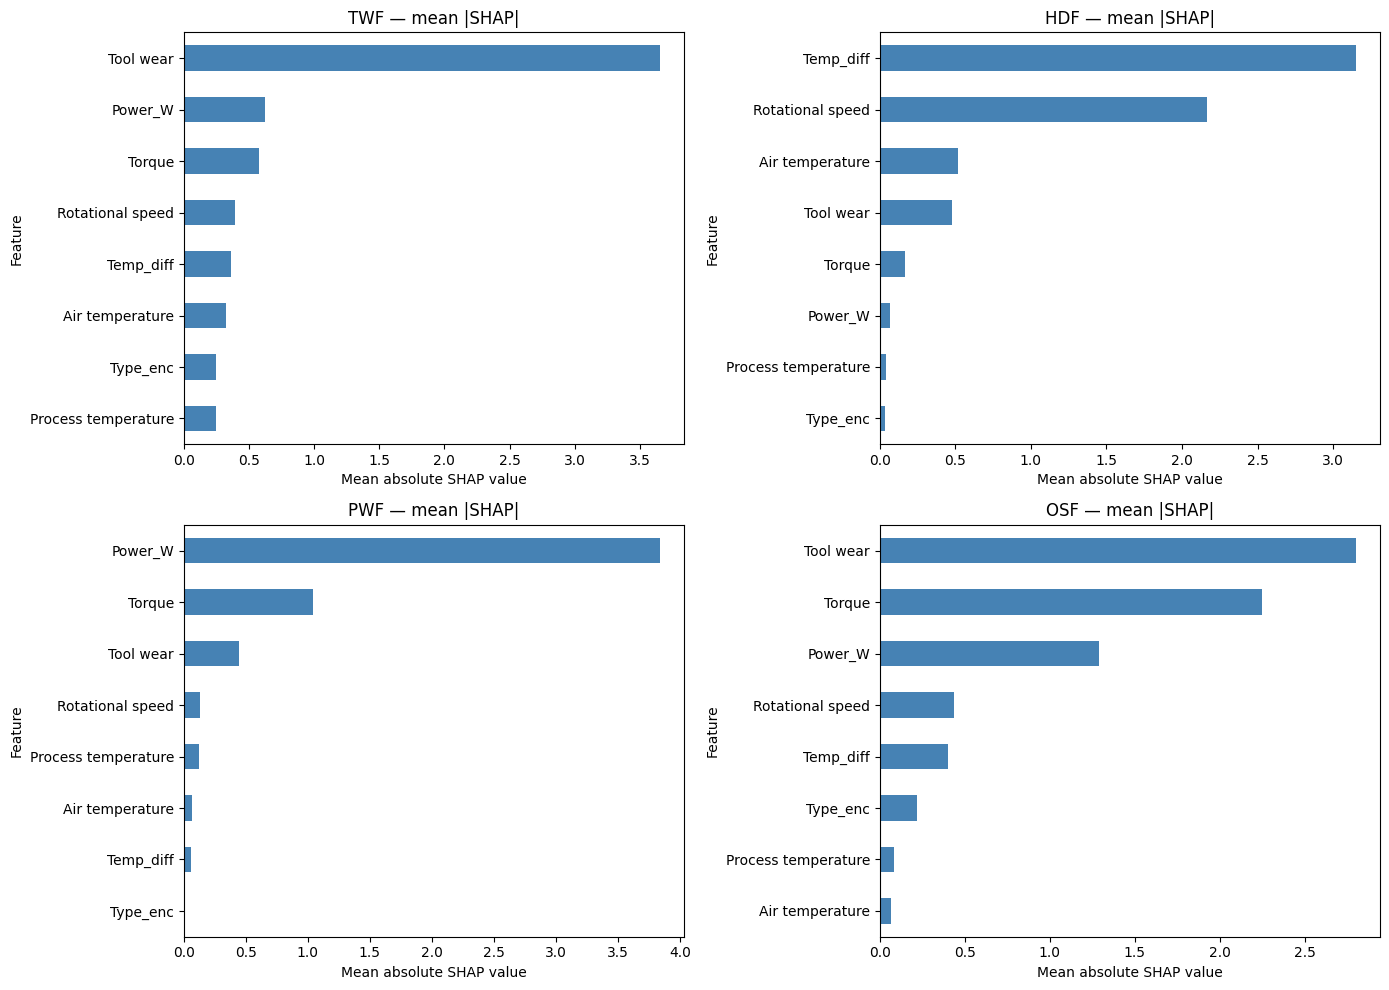

In [25]:
import shap

best_model = joblib.load('best_model.pkl')

# TODO: Compute SHAP values using TreeExplainer
# TODO: Plot 4-subplot bar chart (one per failure class)
# TODO: Save shap_per_class.png
# TODO: Print top driver per class

X_shap = train[FEATURES]
explainer = shap.TreeExplainer(best_model)
shap_output = explainer.shap_values(X_shap)

shap_by_class = np.asarray(shap_output)
if hasattr(shap_output, "values"):
    shap_by_class = np.asarray(shap_output.values)

failure_classes = [1, 2, 3, 4]
class_positions = {
    int(class_id): position for position, class_id in enumerate(best_model.classes_)
}

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for class_id, ax in zip(failure_classes, axes.flat):
    position = class_positions[class_id]
    mean_abs_shap = np.abs(shap_by_class[:, :, position]).mean(axis=0)
    importance = pd.Series(mean_abs_shap, index=FEATURES).sort_values()

    importance.plot(kind="barh", ax=ax, color="steelblue")
    ax.set_title(f"{CLASS_NAMES[class_id]} — mean |SHAP|")
    ax.set_xlabel("Mean absolute SHAP value")
    ax.set_ylabel("Feature")

    print(f"Top driver for {CLASS_NAMES[class_id]}: {importance.idxmax()}")

fig.tight_layout()
fig.savefig("shap_per_class.png", dpi=300, bbox_inches="tight")
plt.show()

### **4.2** <font color=red>[2 marks]</font> Engineering insight

Answer in this markdown cell:

1. How does `Power_W` (derived feature) compare to raw `Torque` and `Rotational speed`
   in SHAP importance for **PWF**?
2. How does `Temp_diff` rank for **HDF** vs other failure types?
3. In 2-3 sentences, describe the physical mechanism behind each failure type based on SHAP.

Suggested structure for your actionable recommendation (used again in Section 5.1.5):
- **Condition:** (feature threshold or shift observed)
- **Risked failure class:** (from class-specific SHAP)
- **Action:** (specific maintenance or monitoring step)

**Answer**

1. **Power_W for PWF:** 'Power_W' combines torque and rotational speed, so it can capture their joint effect on power-related failures. From PWF plot, 'Power_W' ranks first followed by 'Torque' as second and  'Rotational speed' as fourth important feature affecting PWF class.

2. **Temp_diff for HDF:** 'Temp_diff' is physically relevant because it measures the gap between process and air temperatures. Shap impoertance of 'Temp_diff' is highest for HDF class, for other classes it is less significant ( 4th or 5th)

3. **Physical mechanisms:** TWF is associated with accumulated tool wear; HDF with heat-dissipation conditions, reflected in temperatures and their differential. PWF is associated with power-demand conditions represented by torque and rotational speed, while OSF is associated with excessive mechanical load and wear.

**Condition:** The stress batch shows drift in three features: mean rotational speed decreased from 1,539 to 1,497 rpm (Wasserstein score 0.235), mean torque increased from 40.00 to 44.72 Nm (0.474), and mean tool wear increased from 107.68 to 148.87 min (0.645). Air and process temperatures did not drift. These shifts make the tool-wear and torque SHAP drivers relevant to investigate, but they do not establish that failure frequency has increased. 
**Risked failure class:** OSF is a concern as its SHAP plot identifies tool wear as a leading driver.  
**Action:** Increase tool-wear inspections and monitor torque under the shifted operating conditions; confirm the risk against labeled outcomes before changing maintenance thresholds.

## **5. Conclusions** <font color=red>[5 marks]</font>

### **5.1** <font color=red>[5 marks]</font> Key findings

Write a structured conclusion (1 mark per point):

1. Which model won and why - reference macro F1 numbers.
2. Why accuracy is misleading here - operational cost implication.
3. TWF has F1 = 0.0 even after SMOTE + Optuna. Root cause and fix.
   - Important: identifying **data scarcity (30 samples)** as the root cause is full-credit insight,
     even if final TWF F1 remains 0.0.
4. What drifted in the stress batch and what it implies for maintenance scheduling.
5. One actionable recommendation for the engineering team based on SHAP.

## Conclusions

**1. Model selection:**
XGBoost won the model comparison with the highest validation macro F1 (0.7481); Optuna tuning improved its macro F1 to 0.7610.
...

**2. Accuracy vs Macro F1:**
Accuracy is misleading because the classes are highly imbalanced: 6,762 of 6,993 training examples are "No Failure". A model can achieve about 98.4% accuracy while still missing rare failures, including TWF (F1 = 0). Missed failures can cause production downtime costing ₹8–15 lakh per hour, so macro F1 and per-class recall are more useful for assessing operational risk.
...

**3. The TWF problem:**  
This is primarily a data limitation: the training set contains only 30 real TWF examples, too few to represent the range of conditions that precede tool-wear failures. SMOTE can create synthetic examples, but it cannot replace additional independent, correctly labeled events; the model’s TWF F1 therefore remains 0.0. Collect more confirmed TWF cases, including sensor readings and operating context before failure, tool age and maintenance history, and the verified failure type. Then retrain and evaluate on a separate, representative set of real events.
...

**4. Drift and maintenance schedule:**
The stress batch shows drift in **rotational speed** (mean 1,539 to 1,497 rpm), **torque** (40.0 to 44.7 Nm), and **tool wear** (107.7 to 148.9 min); air and process temperatures did not drift. Higher tool wear raises concern for OSF, while the torque and rotational speed shift may affect power-related failure risk. Increase tool-wear inspections and monitor torque during the stress period, but use labeled outcomes to confirm risk before changing preventive-maintenance intervals.
...

**5. Actionable recommendation:**
**Condition:** Tool wear rises under stress (mean ~108 to ~149 min) -> **Risked failure class:** OSF, for which tool wear is a leading SHAP driver -> **Action:** Increase tool-wear inspections and verify the risk against labeled outcomes before changing maintenance intervals.
